# Deer Dataset Evaluation

This notebook evaluates every image in the local deer classification dataset. The broad `deer` label is mapped to the model's `mule_deer` class as a coarse proxy. The dataset has image-level labels rather than bounding boxes, so the result is not object-detection mAP.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from model_services.image import WildlifeDetector  # noqa: E402
from scripts.evaluate_wildlife_folders import (  # noqa: E402
    collect_samples,
    evaluate,
)

DATASET_PATH = (
    PROJECT_ROOT / 'data/datasets/Deer Detection Dataset.v2i.multiclass'
)
REPORT_PATH = PROJECT_ROOT / 'notebooks/results/deer_detection_report.json'
LABEL_MAP = {'train': 'mule_deer'}
CONFIDENCE = 0.25
BATCH_SIZE = 32

print(f'CUDA available: {torch.cuda.is_available()}')
device_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'
print(f'Device: {device_name}')

/home/vivek/Documents/Vivek-projects/WildGuard/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CUDA available: True
Device: NVIDIA GeForce RTX 4090


In [2]:
samples = collect_samples(
    DATASET_PATH,
    label_map=LABEL_MAP,
    samples_per_class=10**9,
    seed=42,
)
print(f'Evaluating {len(samples)} deer images...')
report = evaluate(
    WildlifeDetector(),
    samples,
    batch_size=BATCH_SIZE,
    confidence=CONFIDENCE,
)
report['mapping_note'] = 'dataset deer label mapped to mule_deer proxy'
REPORT_PATH.parent.mkdir(parents=True, exist_ok=True)
REPORT_PATH.write_text(json.dumps(report, indent=2) + '\n', encoding='utf-8')
print(f'Saved report to {REPORT_PATH}')

Evaluating 756 deer images...


WARNING ⚠️ NMS time limit 2.050s exceeded


Saved report to /home/vivek/Documents/Vivek-projects/WildGuard/notebooks/results/deer_detection_report.json


,images,any_detection,target_detected,top1_correct,detection_rate,target_detection_rate,top1_accuracy
deer,756,625,351,326,0.82672,0.464286,0.431217


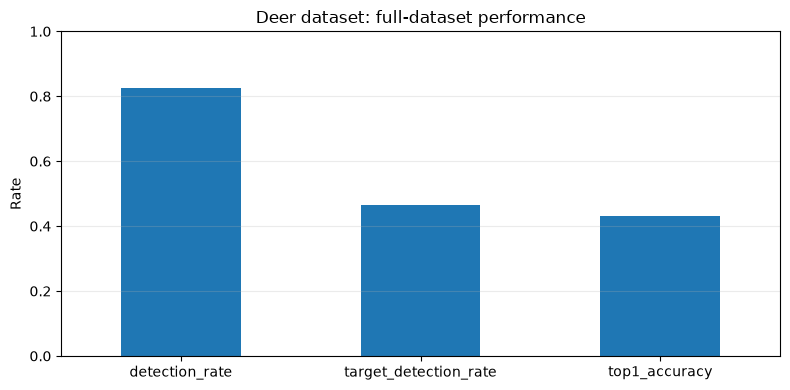

In [3]:
overall_df = pd.DataFrame([report['overall']], index=['deer'])
display(overall_df)

metrics = overall_df.loc['deer', [
    'detection_rate', 'target_detection_rate', 'top1_accuracy'
]]
ax = metrics.plot.bar(figsize=(8, 4), ylim=(0, 1), rot=0)
ax.set_title('Deer dataset: full-dataset performance')
ax.set_ylabel('Rate')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()